In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread('data/img2.png')

kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=np.float32)

In [10]:
sharpened = cv2.filter2D(
    image,
    ddepth=-1,
    kernel=kernel,
)

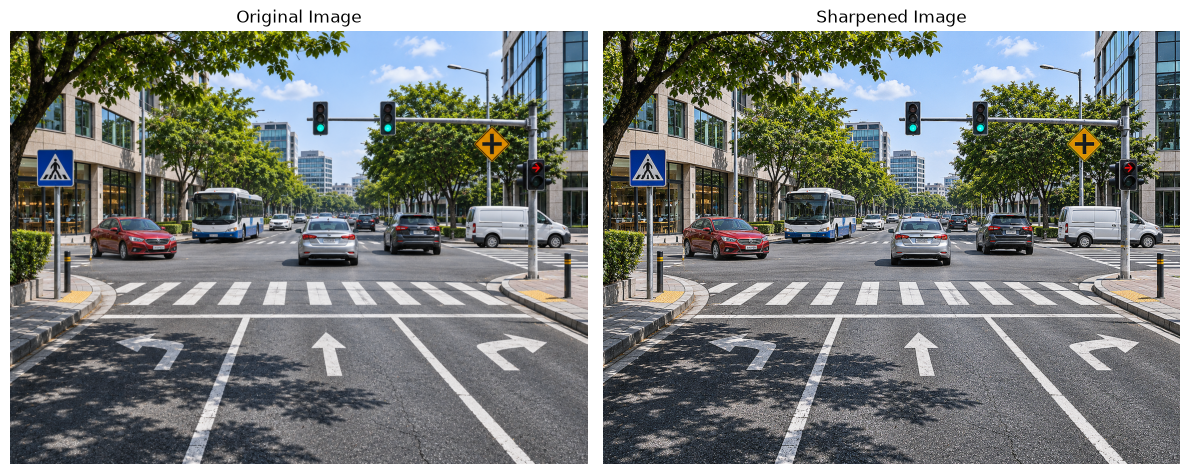

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original Image")

axes[1].imshow(cv2.cvtColor(sharpened, cv2.COLOR_BGR2RGB))
axes[1].set_title("Sharpened Image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Reduce noise before edge detection
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

In [13]:
sobel_x = cv2.Sobel(blurred, cv2.CV_64F, 1, 0)
sobel_y = cv2.Sobel(blurred, cv2.CV_64F, 0, 1)

sobel_x = cv2.convertScaleAbs(sobel_x)
sobel_y = cv2.convertScaleAbs(sobel_y)

In [14]:
laplacian = cv2.Laplacian(blurred, cv2.CV_64F)
laplacian = cv2.convertScaleAbs(laplacian)

In [15]:
canny = cv2.Canny(blurred, 50, 150)

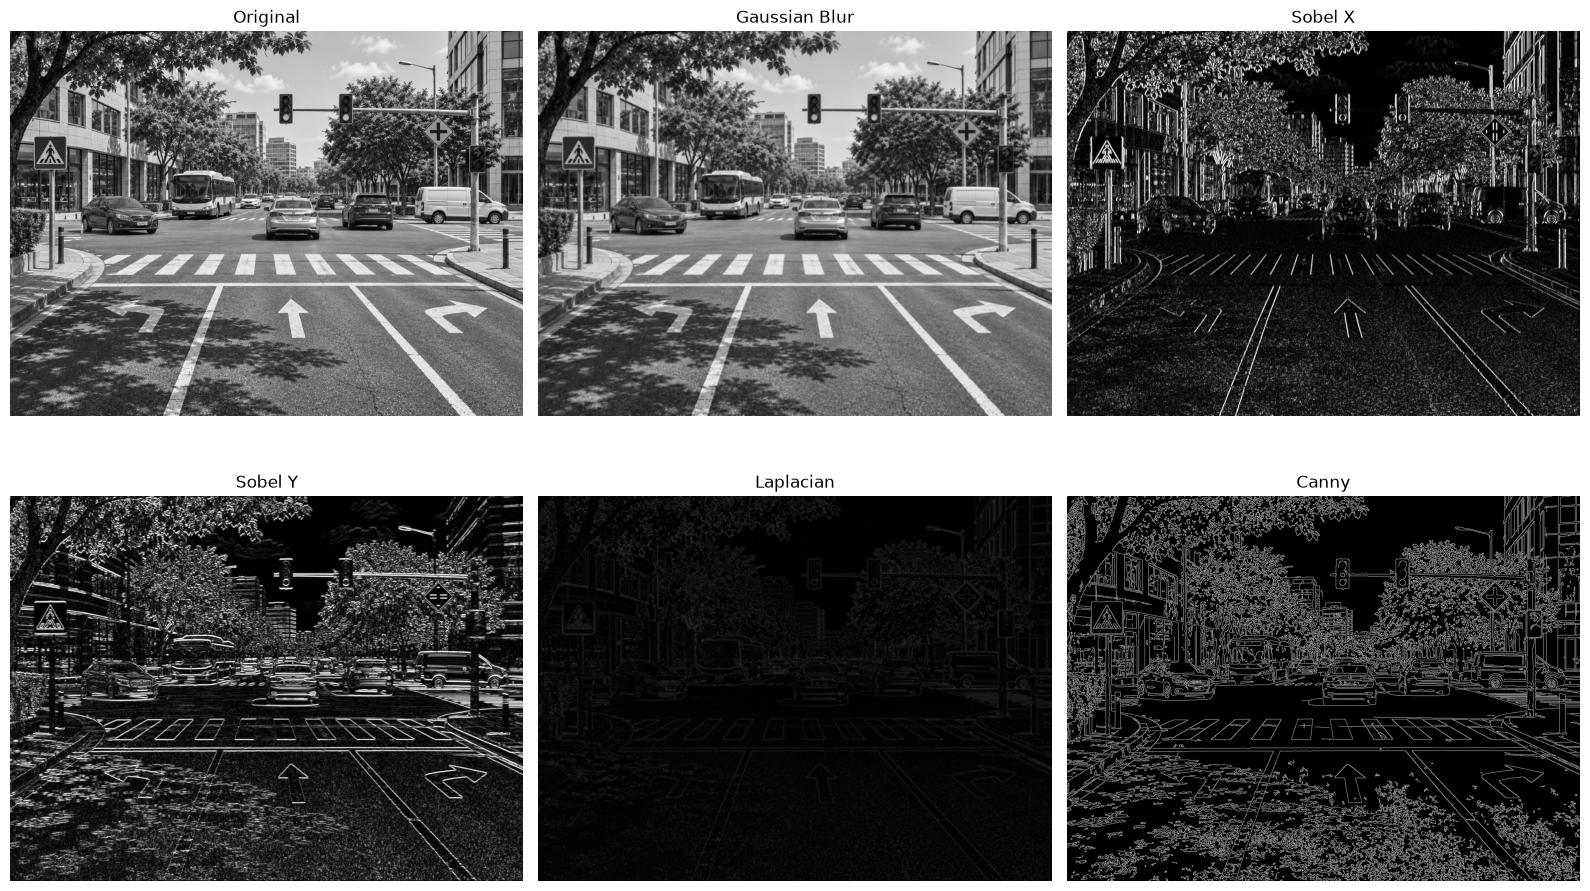

In [16]:
images = [
    ("Original", gray),
    ("Gaussian Blur", blurred),
    ("Sobel X", sobel_x),
    ("Sobel Y", sobel_y),
    ("Laplacian", laplacian),
    ("Canny", canny),
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, (title, img) in zip(axes.ravel(), images):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [17]:
canny_1 = cv2.Canny(blurred, 30, 90)
canny_2 = cv2.Canny(blurred, 50, 150)
canny_3 = cv2.Canny(blurred, 100, 200)

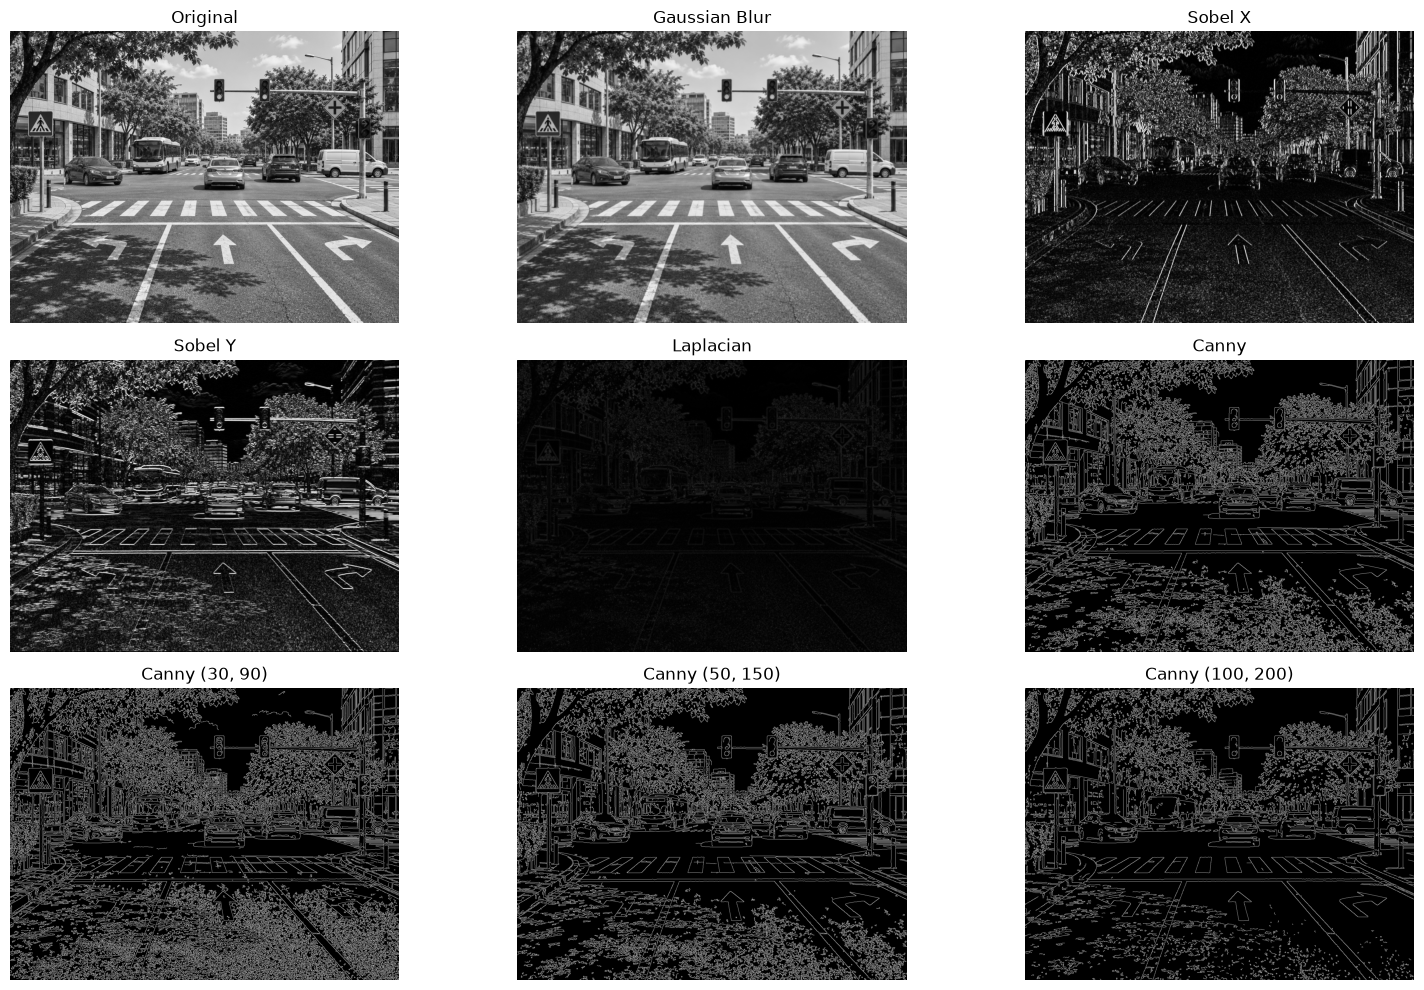

In [19]:
images = [
    ("Original", gray),
    ("Gaussian Blur", blurred),
    ("Sobel X", sobel_x),
    ("Sobel Y", sobel_y),
    ("Laplacian", laplacian),
    ("Canny", canny),
    ("Canny (30, 90)", canny_1),
    ("Canny (50, 150)", canny_2),
    ("Canny (100, 200)", canny_3)
]

fig, axes = plt.subplots(3, 3, figsize=(16, 10))

for ax, (title, img) in zip(axes.ravel(), images):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()